# PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA)
## SV2 - Tuần 02

**Đề tài:** Dự đoán nguy cơ bỏ học và kết quả học tập của sinh viên bằng các mô hình phân lớp.

**Người thực hiện:** Phan Lê Minh Huy (SV2)

### Nguồn dữ liệu
- Dataset: Predict Students' Dropout and Academic Success
- Nguồn: UCI Machine Learning Repository
- UCI ID: 697
- Giấy phép: CC BY 4.0
- Đường dẫn: `data/raw/data.csv`

### Kế thừa kết quả tuần 01
- 4.424 mẫu
- 36 đặc trưng và 1 biến mục tiêu Target
- Graduate: 2.209 mẫu
- Dropout: 1.421 mẫu
- Enrolled: 794 mẫu

### Mục tiêu EDA
1. Thống kê mô tả dữ liệu.
2. Phân tích phân bố Target.
3. Trực quan hóa biến phân loại và biến số.
4. Phân tích tương quan.
5. Kiểm tra dữ liệu thiếu, trùng lặp và ngoại lệ.
6. Bàn giao thông tin đặc trưng cho tiền xử lý.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Tim thu muc goc cua du an
cwd = Path.cwd().resolve()
ROOT = None

for p in [cwd, *cwd.parents]:
    for candidate in [
        p,
        p / "DoAn_MayHoc" / "Nhom01-student-dropout"
    ]:
        if (candidate / "src" / "data.py").exists():
            ROOT = candidate
            break
    if ROOT is not None:
        break

if ROOT is None:
    raise FileNotFoundError("Khong tim thay du an")

sys.path.insert(0, str(ROOT))

from src import config
from src.data import load_data

# Doc dung dataset da tai tu tuan 01
df = load_data()

# Thu muc luu bieu do
FIGURES = config.FIGURES_DIR
FIGURES.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

def save_plot(fig, filename):
    fig.tight_layout()
    fig.savefig(
        FIGURES / filename,
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

print("DA NAP DU LIEU THANH CONG")
print("Kich thuoc:", df.shape)
print("Duong dan:", config.DATA_FILE)
print("Python:", sys.executable)

display(df.head())

DA NAP DU LIEU THANH CONG
Kich thuoc: (4424, 37)
Duong dan: D:\máy học\MLGroup\DoAn_MayHoc\Nhom01-student-dropout\data\raw\data.csv
Python: d:\máy học\MLGroup\DoAn_MayHoc\Nhom01-student-dropout\.venv\Scripts\python.exe


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nationality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [2]:
expected = {
    "Dropout": 1421,
    "Enrolled": 794,
    "Graduate": 2209
}

assert df.shape == (4424, 37), "Sai kich thuoc du lieu"

counts = df[config.TARGET].value_counts()
actual = counts.reindex(config.CLASSES, fill_value=0)

for label, n in expected.items():
    assert actual[label] == n, f"Sai so luong lop {label}"

target_table = pd.DataFrame({
    "So luong": actual,
    "Ty le (%)": (actual / len(df) * 100).round(2)
})

display(target_table)

print("DA XAC MINH DU LIEU KHOP TUAN 01")

,So luong,Ty le (%)
Target,,
Dropout,1421,32.12
Enrolled,794,17.95
Graduate,2209,49.93


DA XAC MINH DU LIEU KHOP TUAN 01


In [3]:

print("=== THONG KE MO TA ===")
display(df.describe(include="all").T)

print("=== KIEM TRA CHAT LUONG ===")

missing_count = int(df.isna().sum().sum())
duplicate_count = int(df.duplicated().sum())

quality_table = pd.DataFrame({
    "Chi tieu": [
        "So dong",
        "So cot",
        "Gia tri thieu",
        "Dong trung lap"
    ],
    "Ket qua": [
        len(df),
        df.shape[1],
        missing_count,
        duplicate_count
    ]
})

display(quality_table)

print("CAC COT CO GIA TRI THIEU:")
display(
    df.isna().sum()
      .loc[lambda s: s > 0]
      .to_frame("So luong thieu")
)


=== THONG KE MO TA ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Marital Status,4424.0,NaN,NaN,NaN,1.178571,0.605747,1.0,1.0,1.0,1.0,6.0
Application mode,4424.0,NaN,NaN,NaN,18.669078,17.484682,1.0,1.0,17.0,39.0,57.0
Application order,4424.0,NaN,NaN,NaN,1.727848,1.313793,0.0,1.0,1.0,2.0,9.0
Course,4424.0,NaN,NaN,NaN,8856.642631,2063.566416,33.0,9085.0,9238.0,9556.0,9991.0
Daytime/evening attendance,4424.0,NaN,NaN,NaN,0.890823,0.311897,0.0,1.0,1.0,1.0,1.0
Previous qualification,4424.0,NaN,NaN,NaN,4.577758,10.216592,1.0,1.0,1.0,1.0,43.0
Previous qualification (grade),4424.0,NaN,NaN,NaN,132.613314,13.188332,95.0,125.0,133.1,140.0,190.0
Nationality,4424.0,NaN,NaN,NaN,1.873192,6.914514,1.0,1.0,1.0,1.0,109.0
Mother's qualification,4424.0,NaN,NaN,NaN,19.561935,15.603186,1.0,2.0,19.0,37.0,44.0
Father's qualification,4424.0,NaN,NaN,NaN,22.275316,15.343108,1.0,3.0,19.0,37.0,44.0


=== KIEM TRA CHAT LUONG ===


,Chi tieu,Ket qua
0,So dong,4424
1,So cot,37
2,Gia tri thieu,0
3,Dong trung lap,0


CAC COT CO GIA TRI THIEU:


,So luong thieu


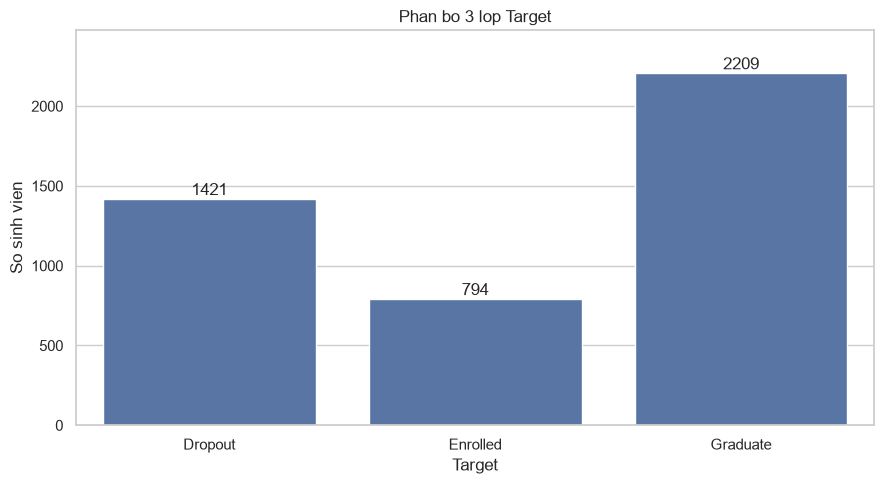

In [4]:

fig, ax = plt.subplots(figsize=(9, 5))

sns.countplot(
    data=df,
    x=config.TARGET,
    order=config.CLASSES,
    ax=ax
)

for bar in ax.patches:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom"
    )

ax.set_title("Phan bo 3 lop Target")
ax.set_xlabel("Target")
ax.set_ylabel("So sinh vien")
ax.set_ylim(0, max(counts) * 1.12)

save_plot(fig, "01_target_distribution.png")


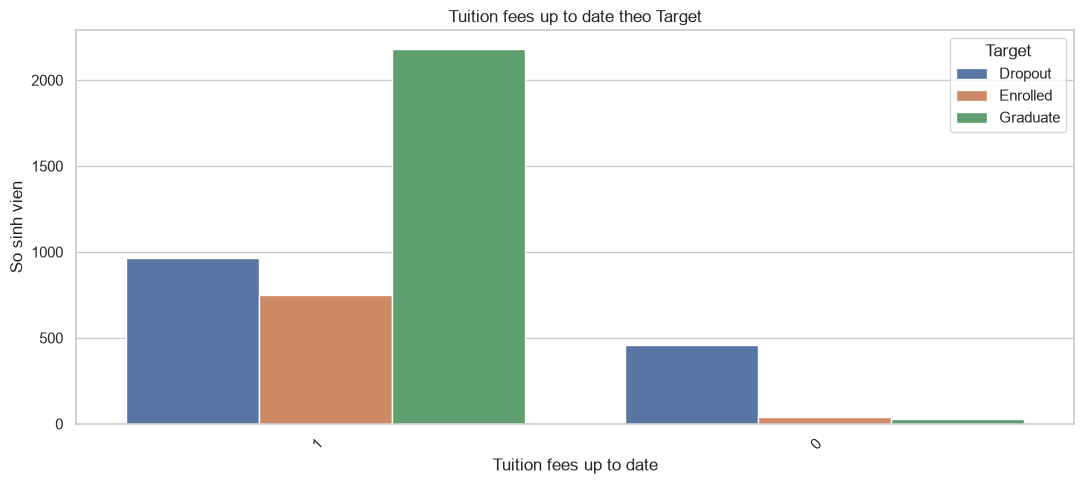

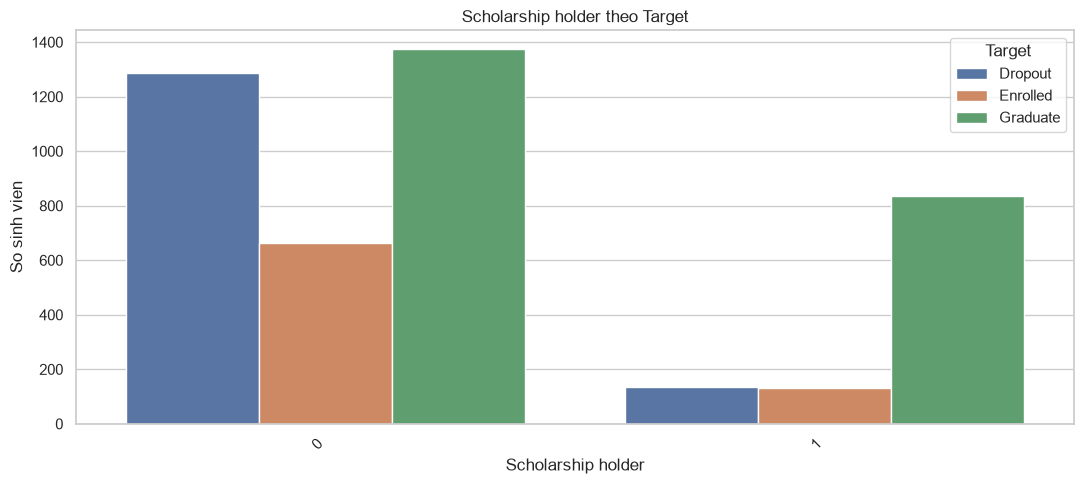

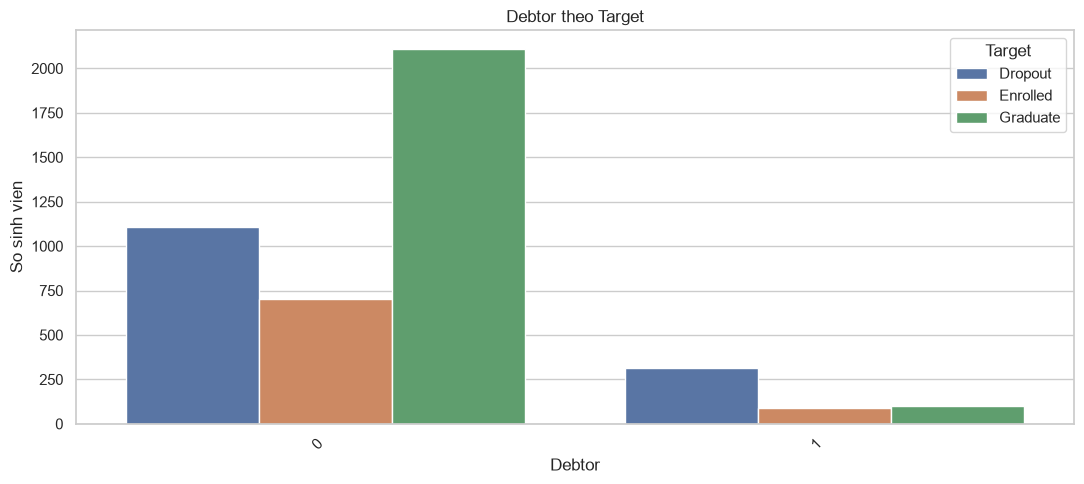

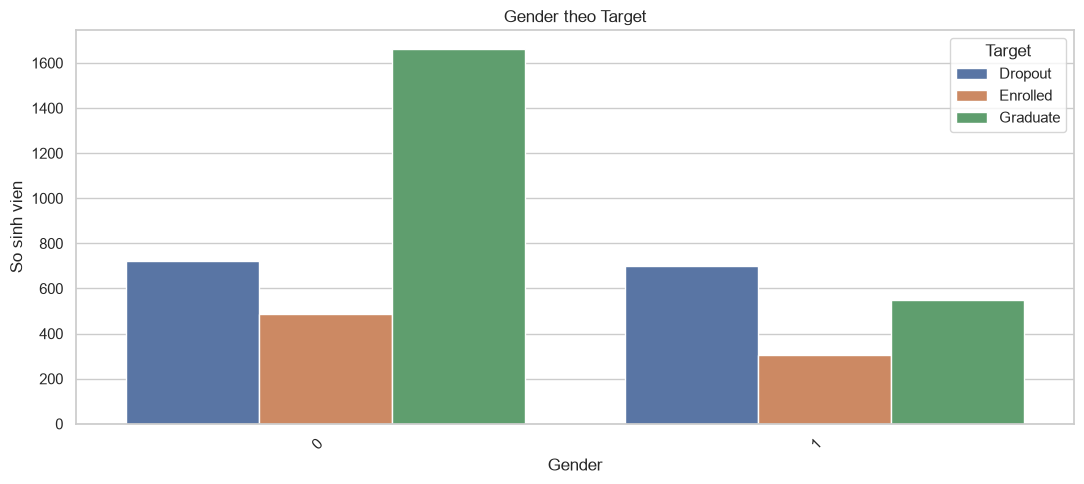

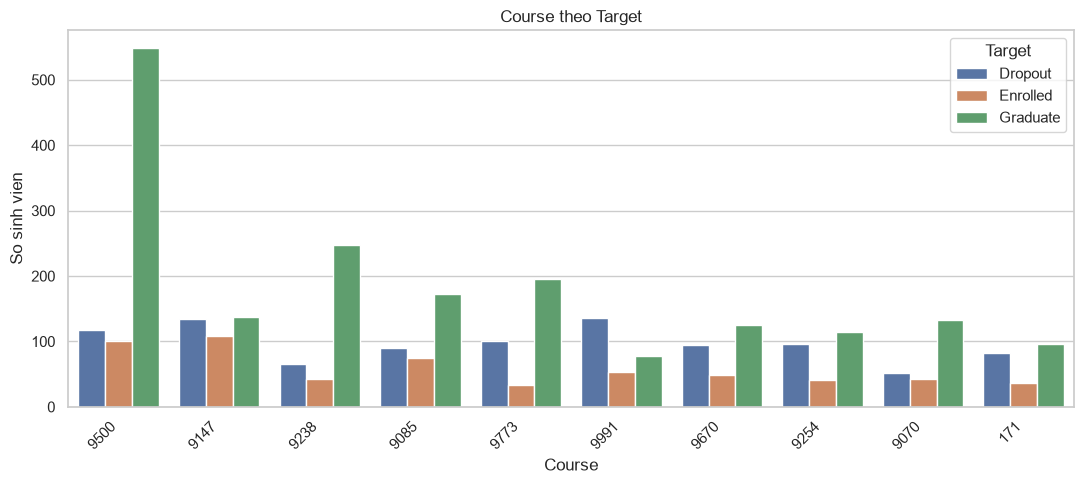

In [5]:

countplot_cols = [
    ("Tuition fees up to date", "02_tuition.png"),
    ("Scholarship holder", "03_scholarship.png"),
    ("Debtor", "04_debtor.png"),
    ("Gender", "05_gender.png"),
    ("Course", "06_course.png")
]

for col, filename in countplot_cols:
    fig, ax = plt.subplots(figsize=(11, 5))

    order = (
        df[col].value_counts().head(10).index.tolist()
    )

    sns.countplot(
        data=df,
        x=col,
        hue=config.TARGET,
        order=order,
        hue_order=config.CLASSES,
        ax=ax
    )

    ax.set_title(f"{col} theo Target")
    ax.set_xlabel(col)
    ax.set_ylabel("So sinh vien")
    ax.legend(title="Target")
    plt.setp(
        ax.get_xticklabels(),
        rotation=45,
        ha="right"
    )

    save_plot(fig, filename)


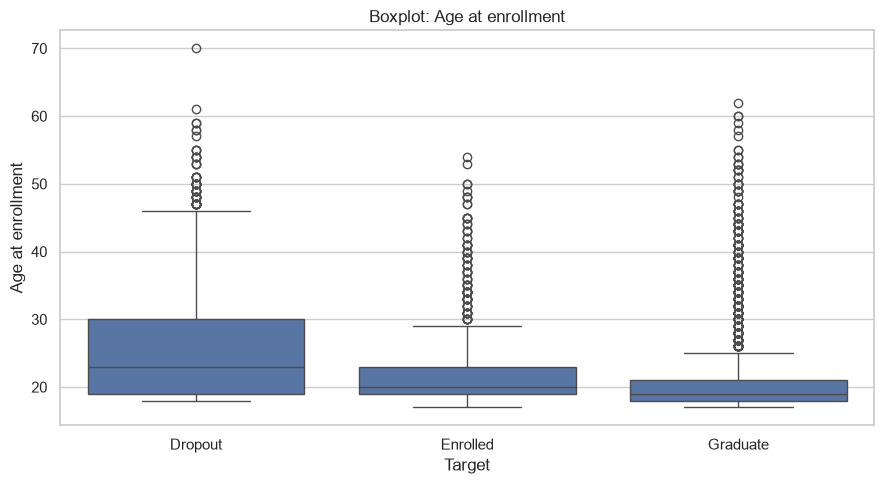

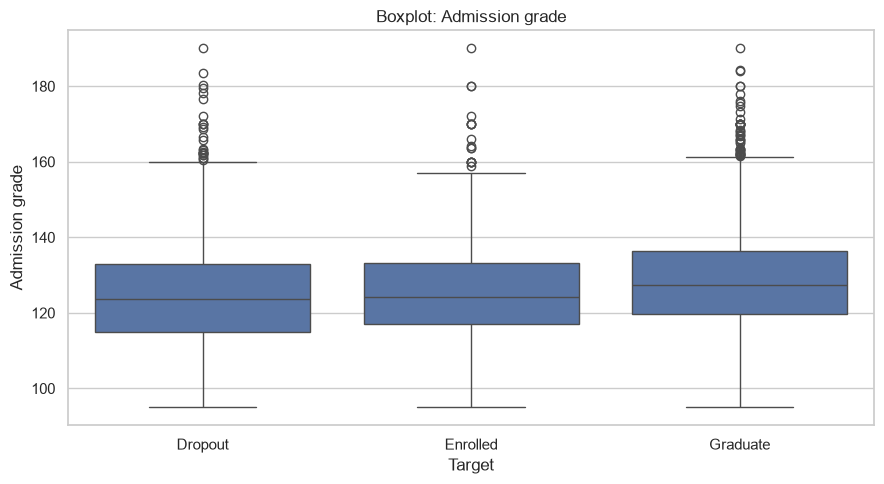

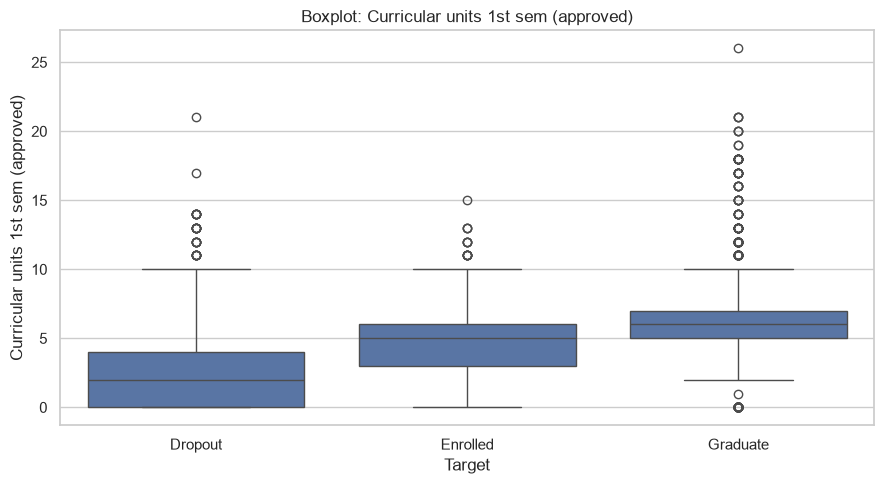

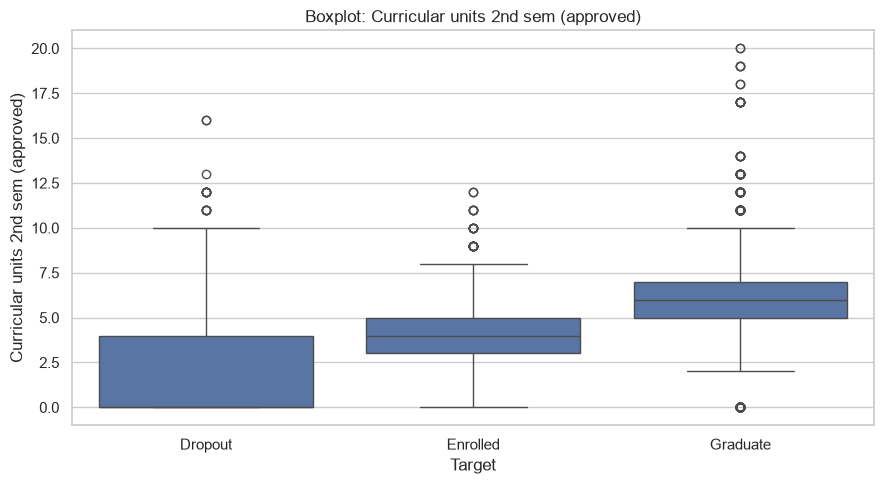

In [6]:

boxplot_cols = [
    ("Age at enrollment", "07_age_box.png"),
    ("Admission grade", "08_admission_box.png"),
    (
        "Curricular units 1st sem (approved)",
        "09_approved_1st_box.png"
    ),
    (
        "Curricular units 2nd sem (approved)",
        "10_approved_2nd_box.png"
    )
]

for col, filename in boxplot_cols:
    fig, ax = plt.subplots(figsize=(9, 5))

    sns.boxplot(
        data=df,
        x=config.TARGET,
        y=col,
        order=config.CLASSES,
        ax=ax
    )

    ax.set_title(f"Boxplot: {col}")
    ax.set_xlabel("Target")
    ax.set_ylabel(col)

    save_plot(fig, filename)


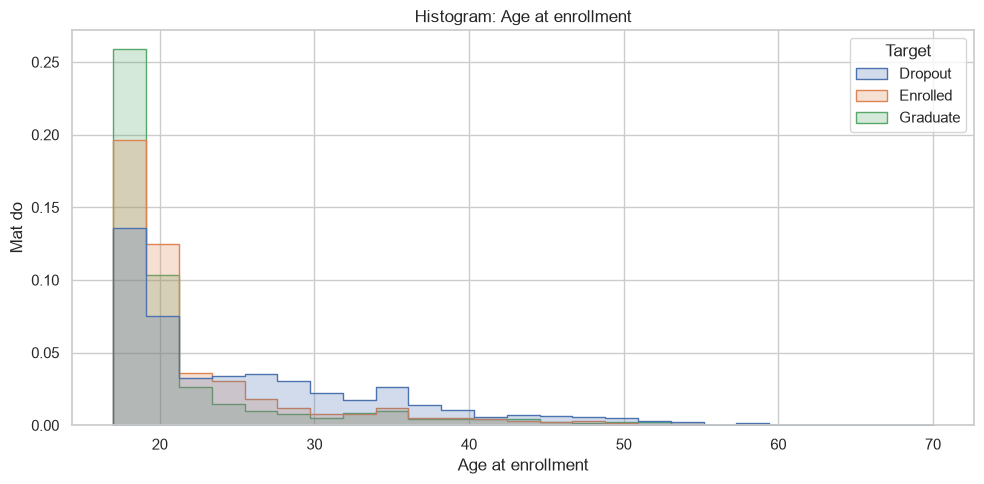

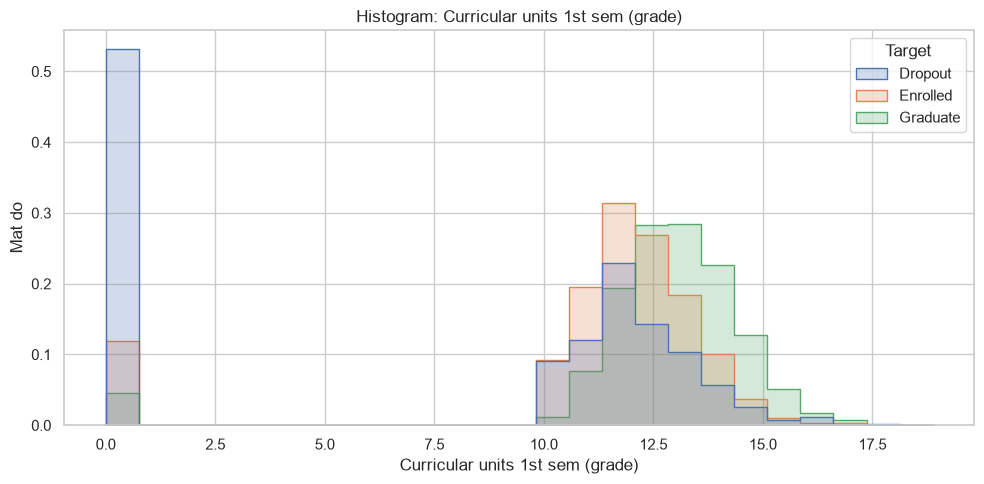

In [7]:

hist_cols = [
    ("Age at enrollment", "11_age_hist.png"),
    (
        "Curricular units 1st sem (grade)",
        "12_grade_1st_hist.png"
    )
]

for col, filename in hist_cols:
    fig, ax = plt.subplots(figsize=(10, 5))

    sns.histplot(
        data=df,
        x=col,
        hue=config.TARGET,
        hue_order=config.CLASSES,
        bins=25,
        stat="density",
        common_norm=False,
        element="step",
        ax=ax
    )

    ax.set_title(f"Histogram: {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Mat do")

    save_plot(fig, filename)


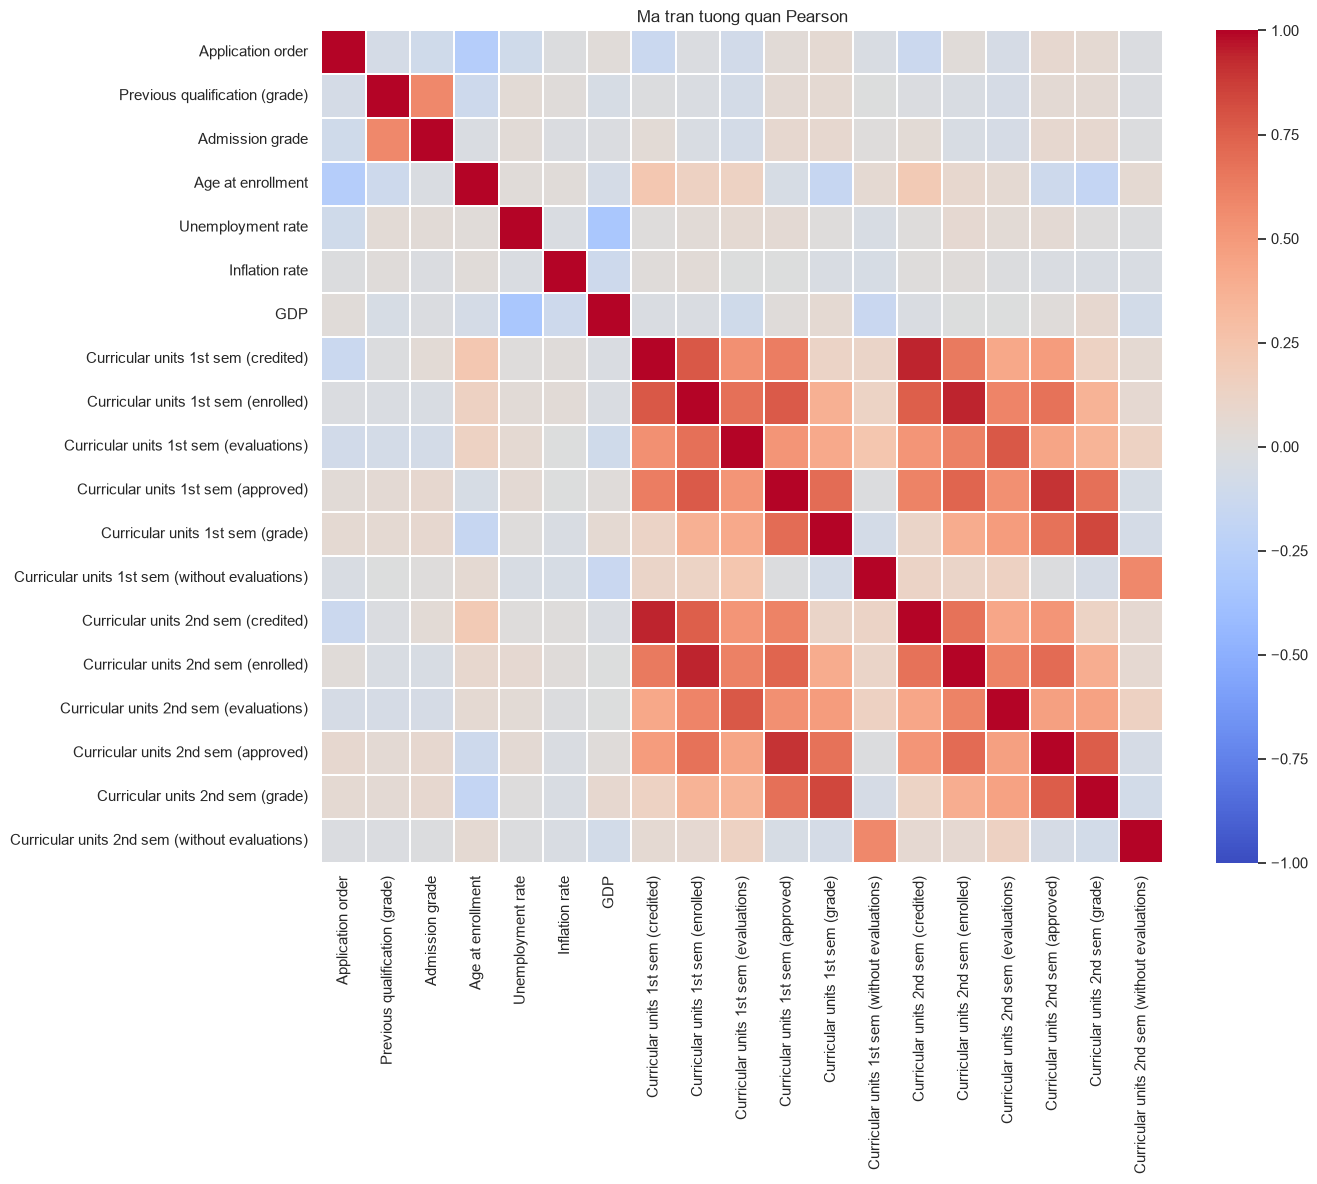

Kich thuoc ma tran: (19, 19)


In [8]:

numeric_cols = (
    config.NUMERIC_COLS
    + config.CURRICULAR_1ST
    + config.CURRICULAR_2ND
)

numeric_cols = [
    col for col in numeric_cols if col in df.columns
]

corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(14, 12))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3,
    ax=ax
)

ax.set_title("Ma tran tuong quan Pearson")

save_plot(fig, "13_correlation.png")

print("Kich thuoc ma tran:", corr.shape)



TY LE TARGET THEO: Scholarship holder


Target,Dropout,Enrolled,Graduate
Scholarship holder,,,
0,38.71,19.97,41.32
1,12.19,11.83,75.98


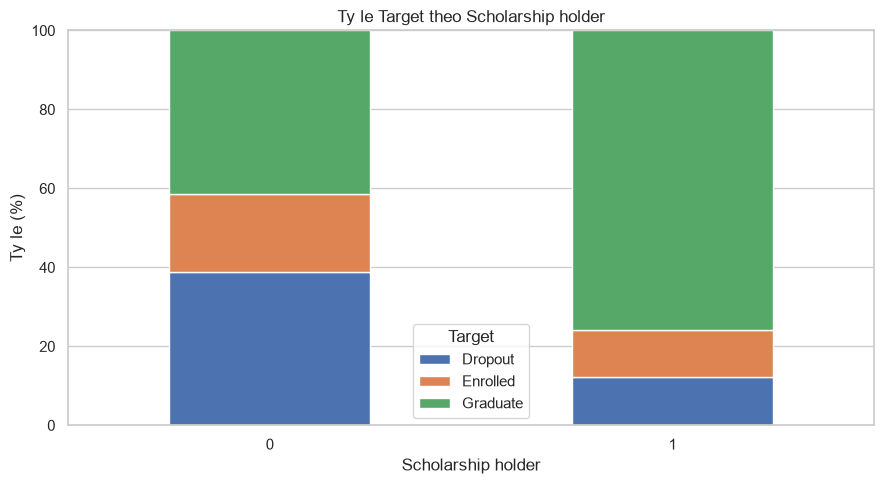


TY LE TARGET THEO: Tuition fees up to date


Target,Dropout,Enrolled,Graduate
Tuition fees up to date,,,
0,86.55,7.95,5.49
1,24.74,19.30,55.95


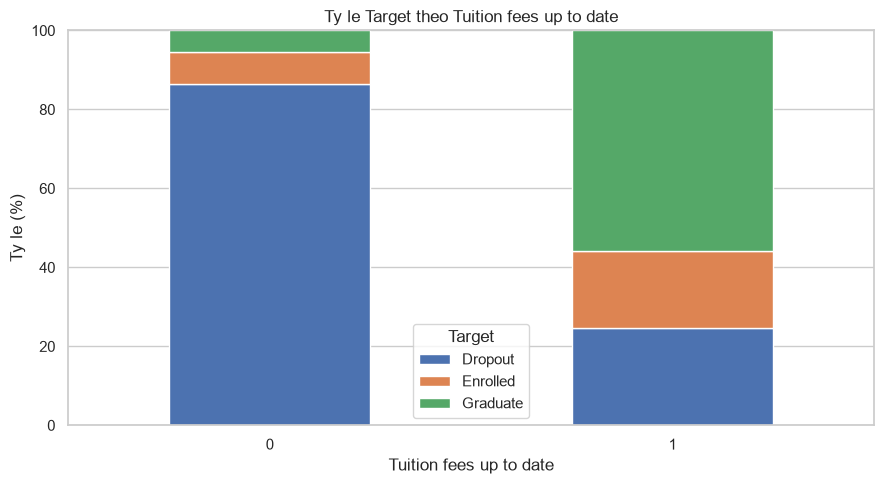

In [9]:

percentage_cols = [
    ("Scholarship holder", "14_scholarship_pct.png"),
    ("Tuition fees up to date", "15_tuition_pct.png")
]

for col, filename in percentage_cols:
    proportions = pd.crosstab(
        df[col],
        df[config.TARGET],
        normalize="index"
    ).reindex(
        columns=config.CLASSES,
        fill_value=0
    ) * 100

    print("\nTY LE TARGET THEO:", col)
    display(proportions.round(2))

    ax = proportions.plot(
        kind="bar",
        stacked=True,
        figsize=(9, 5)
    )

    ax.set_title(f"Ty le Target theo {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Ty le (%)")
    ax.set_ylim(0, 100)
    ax.legend(title="Target")
    ax.tick_params(axis="x", rotation=0)

    save_plot(ax.figure, filename)


In [10]:

outlier_cols = [
    "Age at enrollment",
    "Admission grade",
    "Previous qualification (grade)",
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)"
]

outlier_rows = []

for col in outlier_cols:
    s = df[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr

    n = int(((s < low) | (s > high)).sum())

    outlier_rows.append({
        "Bien": col,
        "Q1": q1,
        "Q3": q3,
        "So ngoai le IQR": n,
        "Ty le (%)": round(n / len(s) * 100, 2)
    })

outlier_table = pd.DataFrame(outlier_rows)

print("=== BANG NGOAI LE ===")
display(outlier_table)

print("=== TRUNG VI THEO TARGET ===")

median_cols = [
    "Age at enrollment",
    "Admission grade",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)"
]

median_table = (
    df.groupby(config.TARGET)[median_cols]
      .median()
      .reindex(config.CLASSES)
      .round(2)
)

display(median_table)

print("EDA chi ghi nhan, khong xoa ngoai le.")


=== BANG NGOAI LE ===


,Bien,Q1,Q3,So ngoai le IQR,Ty le (%)
0,Age at enrollment,19.00,25.000000,441,9.97
1,Admission grade,117.90,134.800000,86,1.94
2,Previous qualification (grade),125.00,140.000000,179,4.05
3,Curricular units 1st sem (approved),3.00,6.000000,180,4.07
4,Curricular units 2nd sem (approved),2.00,6.000000,44,0.99
5,Curricular units 1st sem (grade),11.00,13.400000,726,16.41
6,Curricular units 2nd sem (grade),10.75,13.333333,877,19.82


=== TRUNG VI THEO TARGET ===


,Age at enrollment,Admission grade,Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade)
Target,,,,,,
Dropout,23.0,123.6,2.0,10.93,0.0,0.0
Enrolled,20.0,124.1,5.0,12.00,4.0,12.0
Graduate,19.0,127.4,6.0,13.00,6.0,13.0


EDA chi ghi nhan, khong xoa ngoai le.


In [11]:

groups = {
    "Categorical": config.CATEGORICAL_COLS,
    "Binary": config.BINARY_COLS,
    "Numeric": config.NUMERIC_COLS,
    "Curricular 1st": config.CURRICULAR_1ST,
    "Curricular 2nd": config.CURRICULAR_2ND
}

feature_rows = []

for group_name, columns in groups.items():
    for col in columns:
        feature_rows.append({
            "Ten bien": col,
            "Nhom": group_name,
            "Co trong du lieu": col in df.columns
        })

feature_table = pd.DataFrame(feature_rows)

print("=== DANH SACH DAC TRUNG ===")
display(feature_table)

print("\n=== SO BIEN THEO NHOM ===")
display(
    feature_table["Nhom"]
    .value_counts()
    .to_frame("So bien")
)

print("Tong so dac trung:", len(feature_table))

assert len(feature_table) == 36
assert feature_table["Co trong du lieu"].all()
assert feature_table["Ten bien"].is_unique

print("DA DOI CHIEU XONG CONFIG.PY")


=== DANH SACH DAC TRUNG ===


,Ten bien,Nhom,Co trong du lieu
0,Marital Status,Categorical,True
1,Application mode,Categorical,True
2,Course,Categorical,True
3,Daytime/evening attendance,Categorical,True
4,Previous qualification,Categorical,True
5,Nationality,Categorical,True
6,Mother's qualification,Categorical,True
7,Father's qualification,Categorical,True
8,Mother's occupation,Categorical,True
9,Father's occupation,Categorical,True



=== SO BIEN THEO NHOM ===


,So bien
Nhom,
Categorical,10
Binary,7
Numeric,7
Curricular 1st,6
Curricular 2nd,6


Tong so dac trung: 36
DA DOI CHIEU XONG CONFIG.PY


In [12]:

print("=== CAC CAP BIEN TUONG QUAN CAO ===")

mask = np.triu(
    np.ones(corr.shape, dtype=bool),
    k=1
)

corr_pairs = (
    corr.where(mask)
        .stack()
        .reset_index()
)

corr_pairs.columns = [
    "Bien 1",
    "Bien 2",
    "Pearson r"
]

corr_pairs["|r|"] = corr_pairs["Pearson r"].abs()

corr_top = (
    corr_pairs
    .sort_values("|r|", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

display(corr_top.round(4))

print("\n=== MA PHAN LOAI HIEM (<20 MAU) ===")

rare_rows = []

for col in config.CATEGORICAL_COLS:
    freq = df[col].value_counts(dropna=False)

    for code, n in freq.items():
        if n < 20:
            rare_rows.append({
                "Bien": col,
                "Ma": code,
                "So luong": int(n),
                "Ty le (%)": round(n / len(df) * 100, 3)
            })

rare_table = pd.DataFrame(
    rare_rows,
    columns=[
        "Bien",
        "Ma",
        "So luong",
        "Ty le (%)"
    ]
)

rare_table = rare_table.sort_values(
    ["Bien", "So luong"]
).reset_index(drop=True)

print("Tong so ma hiem:", len(rare_table))
display(rare_table)

print(
    "Chi thong ke ma hiem, "
    "KHONG gop nhom hay sua du lieu."
)


=== CAC CAP BIEN TUONG QUAN CAO ===


,Bien 1,Bien 2,Pearson r,|r|
0,Curricular units 1st sem (credited),Curricular units 2nd sem (credited),0.9448,0.9448
1,Curricular units 1st sem (enrolled),Curricular units 2nd sem (enrolled),0.9426,0.9426
2,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),0.9040,0.9040
3,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),0.8372,0.8372
4,Curricular units 1st sem (evaluations),Curricular units 2nd sem (evaluations),0.7789,0.7789
5,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),0.7743,0.7743
6,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),0.7691,0.7691
7,Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),0.7608,0.7608
8,Curricular units 1st sem (enrolled),Curricular units 2nd sem (credited),0.7537,0.7537
9,Curricular units 1st sem (approved),Curricular units 2nd sem (enrolled),0.7338,0.7338



=== MA PHAN LOAI HIEM (<20 MAU) ===
Tong so ma hiem: 134


,Bien,Ma,So luong,Ty le (%)
0,Application mode,57,1,0.023
1,Application mode,26,1,0.023
2,Application mode,27,1,0.023
3,Application mode,2,3,0.068
4,Application mode,10,10,0.226
...,...,...,...,...
129,Previous qualification,43,6,0.136
130,Previous qualification,38,7,0.158
131,Previous qualification,4,8,0.181
132,Previous qualification,9,11,0.249


Chi thong ke ma hiem, KHONG gop nhom hay sua du lieu.


In [ ]:

report_path = config.RESULTS_DIR / "01_eda.md"

lines = [
    "# BÀN GIAO EDA SV2 - TUẦN 02",
    "",
    "## Thông tin",
    "- Người thực hiện: Phan Lê Minh Huy (SV2)",
    "- Issue: #3",
    "- Dataset: UCI 697",
    f"- Số mẫu: {len(df)}",
    f"- Số đặc trưng: {df.shape[1] - 1}",
    f"- Giá trị thiếu: {missing_count}",
    f"- Dòng trùng lặp: {duplicate_count}",
    "",
    "## Danh sách nhóm biến",
    ""
]

for name, cols in groups.items():
    lines.append(f"### {name} ({len(cols)} biến)")
    for col in cols:
        lines.append(f"- `{col}`")
    lines.append("")

lines.extend([
    "## Các cặp biến tương quan cao",
    "",
    "| Biến 1 | Biến 2 | Pearson r |",
    "|---|---|---:|"
])

for _, row in corr_top.iterrows():
    lines.append(
        f"| {row['Bien 1']} | {row['Bien 2']} | "
        f"{row['Pearson r']:.4f} |"
    )

lines.extend([
    "",
    "## Mã phân loại hiếm (dưới 20 mẫu)",
    "",
    "| Biến | Mã | Số lượng |",
    "|---|---|---:|"
])

for _, row in rare_table.iterrows():
    lines.append(
        f"| {row['Bien']} | {row['Ma']} | "
        f"{int(row['So luong'])} |"
    )

lines.extend([
    "",
    "## Lưu ý cho tiền xử lý",
    "- Dùng danh sách nhóm biến trong src/config.py.",
    "- Biến phân loại mã hóa số không phải biến liên tục.",
    "- Cân nhắc các mã hiếm theo ngưỡng min_frequency=20.",
    "- Kiểm tra các cặp biến tương quan cao.",
    "- Không xóa ngoại lệ chỉ dựa trên quy tắc IQR.",
    "- Không sửa data/raw/data.csv.",
    "- Fit các bước tiền xử lý trên tập train.",
    ""
])

report_path.parent.mkdir(parents=True, exist_ok=True)

report_path.write_text(
    "\n".join(lines),
    encoding="utf-8"
)

print("DA TAO BAO CAO BAN GIAO")
print("Duong dan:", report_path)
print("So nhom bien:", len(groups))
print("Tong so dac trung:", len(feature_table))
print("So ma hiem:", len(rare_table))
print("So cap tuong quan ban giao:", len(corr_top))


DA TAO BAO CAO BAN GIAO
Duong dan: D:\máy học\MLGroup\DoAn_MayHoc\Nhom01-student-dropout\reports\eda_sv2_week2_handoff.md
So nhom bien: 5
Tong so dac trung: 36
So ma hiem: 134
So cap tuong quan ban giao: 15


In [14]:

expected_figures = [
    "01_target_distribution.png",
    "02_tuition.png",
    "03_scholarship.png",
    "04_debtor.png",
    "05_gender.png",
    "06_course.png",
    "07_age_box.png",
    "08_admission_box.png",
    "09_approved_1st_box.png",
    "10_approved_2nd_box.png",
    "11_age_hist.png",
    "12_grade_1st_hist.png",
    "13_correlation.png",
    "14_scholarship_pct.png",
    "15_tuition_pct.png"
]

existing = [
    f for f in expected_figures
    if (FIGURES / f).exists()
]

missing_figures = [
    f for f in expected_figures
    if f not in existing
]

print("=== KIEM TRA EDA TUAN 02 ===")
print("Da tao:", len(existing), "/15 bieu do")
print("Duong dan:", FIGURES)

for filename in expected_figures:
    status = "OK" if filename in existing else "THIEU"
    print(status, filename)

print("\nBao cao SV3:", report_path.exists())
print("Dataset:", df.shape)

if not missing_figures and report_path.exists():
    print("\nHOAN THANH SAN PHAM EDA TUAN 02")
else:
    print("\nCAN KIEM TRA LAI CAC CELL CHUA CHAY")


=== KIEM TRA EDA TUAN 02 ===
Da tao: 15 /15 bieu do
Duong dan: D:\máy học\MLGroup\DoAn_MayHoc\Nhom01-student-dropout\reports\figures
OK 01_target_distribution.png
OK 02_tuition.png
OK 03_scholarship.png
OK 04_debtor.png
OK 05_gender.png
OK 06_course.png
OK 07_age_box.png
OK 08_admission_box.png
OK 09_approved_1st_box.png
OK 10_approved_2nd_box.png
OK 11_age_hist.png
OK 12_grade_1st_hist.png
OK 13_correlation.png
OK 14_scholarship_pct.png
OK 15_tuition_pct.png

Bao cao SV3: True
Dataset: (4424, 37)

HOAN THANH SAN PHAM EDA TUAN 02



## NHẬN XÉT VÀ KẾT LUẬN EDA – TUẦN 02

### 1. Tổng quan dữ liệu
Bộ dữ liệu UCI ID 697 gồm 4.424 sinh viên, 36 đặc trưng và một biến mục tiêu Target. Kích thước và phân bố nhãn phù hợp với kết quả xác minh tuần 01.

### 2. Phân bố Target
- Graduate: 2.209 mẫu (49,93%).
- Dropout: 1.421 mẫu (32,12%).
- Enrolled: 794 mẫu (17,95%).

Dữ liệu có hiện tượng mất cân bằng lớp. Graduate chiếm tỷ lệ lớn nhất, trong khi Enrolled có ít mẫu nhất.

### 3. Chất lượng dữ liệu
- Tổng số giá trị thiếu: 0.
- Tổng số dòng trùng lặp: 0.
- Ngoại lệ được kiểm tra theo phương pháp IQR.

Các giá trị ngoại lệ chỉ được ghi nhận trong EDA, không tự động loại bỏ hoặc thay đổi.

### 4. Phân tích các biến số
Trung vị tuổi nhập học của nhóm Dropout là 23 tuổi, cao hơn Graduate (19 tuổi).

Trung vị số môn đạt học kỳ 1:
- Dropout: 2 môn.
- Enrolled: 5 môn.
- Graduate: 6 môn.

Trung vị điểm học kỳ 1:
- Dropout: khoảng 10,93.
- Enrolled: 12.
- Graduate: 13.

Những khác biệt này cho thấy các biến kết quả học tập có khả năng cung cấp thông tin phân biệt giữa các lớp, nhưng cần được kiểm chứng bằng mô hình.

### 5. Phân tích tương quan
Một số biến kết quả học tập giữa hai học kỳ có tương quan dương cao:

- Tín chỉ được công nhận HK1/HK2: r ≈ 0,9448.
- Số môn đăng ký HK1/HK2: r ≈ 0,9426.
- Số môn đạt HK1/HK2: r ≈ 0,9040.
- Điểm HK1/HK2: r ≈ 0,8372.

Cần lưu ý các mối tương quan này trong quá trình xây dựng và lựa chọn đặc trưng, nhưng không mặc nhiên loại biến chỉ vì tương quan cao.

### 6. Đặc điểm lớp Enrolled
Enrolled là lớp ít mẫu nhất. Trung vị của một số biến kết quả học tập nằm giữa Dropout và Graduate.

Tuy nhiên, chưa thể khẳng định lớp Enrolled khó phân loại nhất nếu chưa đánh giá mô hình và xem xét mức độ chồng lấn đa chiều.

### 7. Bàn giao cho tiền xử lý
Đã thống kê:
- 10 biến phân loại mã hóa số.
- 7 biến nhị phân.
- 7 biến số/thứ tự.
- 12 biến kết quả học tập trong hai học kỳ.
- Các cặp biến có tương quan cao.
- Các mã phân loại xuất hiện dưới 20 lần.

Danh sách chi tiết được lưu tại `reports/eda_sv2_week2_handoff.md`.

### 8. Kết luận
Phân tích EDA đã cung cấp cái nhìn tổng quan về dữ liệu, phân bố Target, chất lượng dữ liệu, quan hệ giữa các biến và những vấn đề cần lưu ý cho tiền xử lý.

Dữ liệu gốc được giữ nguyên. Các bước mã hóa, chuẩn hóa, gộp nhóm và huấn luyện mô hình được thực hiện riêng trong Pipeline của nhóm, tránh rò rỉ thông tin từ tập kiểm tra.
